# Colab Intro


Suma $S_{n}$ pierwszych $n$ wyrazów ciągu geometrycznego $a_{n}$ zależy od ilorazu $q$:

- Gdy iloraz $q \neq 1$:

$$
S_{n} = a_{1} \cdot \frac{1-q^{n}}{1-q}
$$

- Gdy iloraz $q = 1$(ciąg stały):

$$
S_{n} = n \cdot a_{1}
$$


In [ ]:
import math

print(2+2)


4


In [ ]:
print(math.pow(math.pi,math.pi))

36.4621596072079


In [ ]:
a = 1
suma = 0
while a < 101:
  suma = suma + math.pow(a, 2)
  a = a + 1
print(suma)

338350.0


In [ ]:
with open("colab_wynik.txt", "w", encoding="utf-8") as f:
  f.write(str(suma))

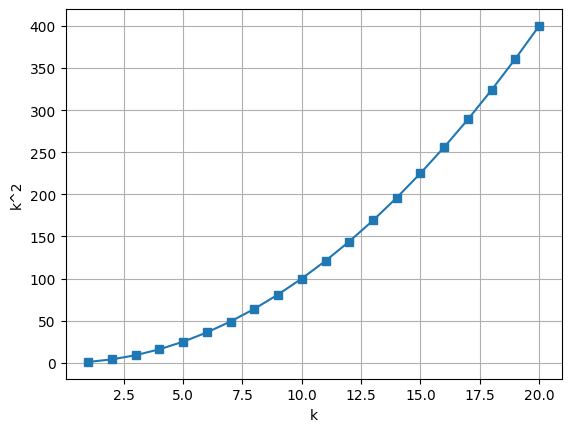

In [ ]:
import matplotlib.pyplot as plt

k = list(range(1,21))
y = [val**2 for val in k]

plt.plot(k, y, marker="s")
plt.ylabel("k^2")
plt.xlabel("k")
plt.grid()
plt.savefig("wykres.png", dpi=150, bbox_inches="tight")
plt.show()


In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.animation as animation
from matplotlib.collections import LineCollection
from IPython.display import HTML
from base64 import b64encode

# Parametry symulacji fizycznej wahadła
g = 9.81
L = 1.0
theta0 = np.radians(60)
omega0 = 0.0

t_max = 10.0
fps = 30
dt = 1.0 / fps
t = np.arange(0.0, t_max, dt)

# Uproszczone rozwiązanie RK4
def derivatives(theta, omega):
    return omega, -(g / L) * np.sin(theta)

theta = np.zeros_like(t)
omega = np.zeros_like(t)
theta[0] = theta0
omega[0] = omega0

for i in range(1, len(t)):
    k1_theta, k1_omega = derivatives(theta[i-1], omega[i-1])
    k2_theta, k2_omega = derivatives(theta[i-1] + 0.5 * dt * k1_theta, omega[i-1] + 0.5 * dt * k1_omega)
    k3_theta, k3_omega = derivatives(theta[i-1] + 0.5 * dt * k2_theta, omega[i-1] + 0.5 * dt * k2_omega)
    k4_theta, k4_omega = derivatives(theta[i-1] + dt * k3_theta, omega[i-1] + dt * k3_omega)

    theta[i] = theta[i-1] + (dt / 6.0) * (k1_theta + 2.0 * k2_theta + 2.0 * k3_theta + k4_theta)
    omega[i] = omega[i-1] + (dt / 6.0) * (k1_omega + 2.0 * k2_omega + 2.0 * k3_omega + k4_omega)

x = L * np.sin(theta)
y = -L * np.cos(theta)

fig, ax = plt.subplots(figsize=(6, 6))
ax.set_xlim(-1.2, 1.2)
ax.set_ylim(-1.2, 0.2)
ax.set_aspect('equal')
ax.grid(True, linestyle='--', alpha=0.5, color='gray')

# Jawne ustawienie kolorów dla osi, tekstu i etykiet na czarny
ax.set_title("Tęczowe Wahadło", fontsize=14, color='black')
ax.set_xlabel("X", color='black')
ax.set_ylabel("Y", color='black')
ax.tick_params(colors='black')
for spine in ax.spines.values():
    spine.set_color('black')

# Ramię wahadła (czarne)
line, = ax.plot([], [], 'o-', color='black', lw=2, zorder=4)
# Kulka wahadła (czarna obwódka, czerwony środek)
bob = ax.scatter([], [], color='red', edgecolors='black', s=100, zorder=5)

# Przygotowanie tęczowego śladu
trail_len = 30
colors = plt.cm.rainbow(np.linspace(0, 1, trail_len))
lc = LineCollection([], colors=colors, linewidths=3, zorder=3)
ax.add_collection(lc)

def init():
    line.set_data([], [])
    lc.set_segments([])
    return line, lc

def animate(i):
    line.set_data([0, x[i]], [0, y[i]])
    bob.set_offsets([[x[i], y[i]]])

    if i > 1:
        start_idx = max(0, i - trail_len)
        history_x = x[start_idx:i+1]
        history_y = y[start_idx:i+1]

        points = np.array([history_x, history_y]).T.reshape(-1, 1, 2)
        segments = np.concatenate([points[:-1], points[1:]], axis=1)

        lc.set_segments(segments)
        if len(segments) < trail_len:
            lc.set_colors(colors[-len(segments):])
        else:
            lc.set_colors(colors)
    else:
        lc.set_segments([])

    return line, lc, bob

ani = animation.FuncAnimation(fig, animate, init_func=init, frames=len(t), interval=1000/fps, blit=True)

# Zapisanie skorygowanego wideo
writer = animation.FFMpegWriter(fps=fps, metadata=dict(artist='Colab'), bitrate=1800)
ani.save('video.mp4', writer=writer)
plt.close()

print("Animacja pomyślnie zapisana do pliku 'video.mp4'.")

Animacja pomyślnie zapisana do pliku 'video.mp4'.


In [ ]:
# Wyświetlenie wideo bezpośrednio w komórce Colab
with open('video.mp4', 'rb') as f:
    video_bytes = f.read()

data_url = "data:video/mp4;base64," + b64encode(video_bytes).decode()
HTML(f"""
<video width="500" controls autoplay loop>
      <source src="{data_url}" type="video/mp4">
</video>
""")

/usr/local/lib/python3.13/dist-packages/moviepy/config_defaults.py:47: SyntaxWarning: invalid escape sequence '\P'
  IMAGEMAGICK_BINARY = r"C:\Program Files\ImageMagick-6.8.8-Q16\magick.exe"
/usr/local/lib/python3.13/dist-packages/moviepy/video/io/ffmpeg_reader.py:294: SyntaxWarning: invalid escape sequence '\d'
  lines_video = [l for l in lines if ' Video: ' in l and re.search('\d+x\d+', l)]
/usr/local/lib/python3.13/dist-packages/moviepy/video/io/ffmpeg_reader.py:367: SyntaxWarning: invalid escape sequence '\d'
  rotation_lines = [l for l in lines if 'rotate          :' in l and re.search('\d+$', l)]
/usr/local/lib/python3.13/dist-packages/moviepy/video/io/ffmpeg_reader.py:370: SyntaxWarning: invalid escape sequence '\d'
  match = re.search('\d+$', rotation_line)
  if event.key is 'enter':



MoviePy - Building file video.gif with imageio.


Plik video.gif został utworzony!


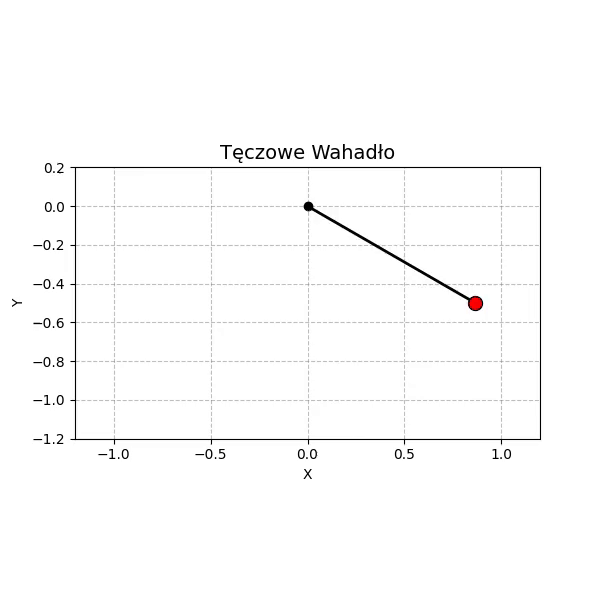

In [ ]:
import warnings
# Ukrywamy ostrzeżenia oparte na przestarzałych API (np. z pygame), aby nie brudziły podglądu kodu i wyniku
warnings.filterwarnings("ignore", category=UserWarning)

from moviepy.editor import VideoFileClip
from IPython.display import Image, display

# Wczytanie wideo i konwersja do GIF z optymalnym próbkowaniem kolorów
clip = VideoFileClip("video.mp4")
clip.write_gif(
    "video.gif",
    fps=15,
    program='imageio',
    opt='colors',
    fuzz=1
)
clip.close()

print("Plik video.gif został utworzony!")

# Wyświetlenie gifa bezpośrednio w komórce jako statyczny załącznik (widoczny na GitHubie)
display(Image(filename="video.gif"))

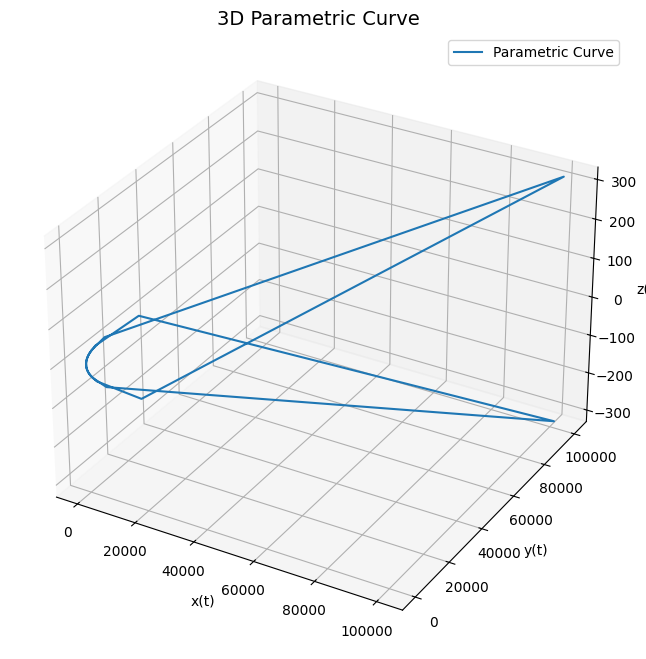

In [ ]:
# Correcting the label for rendering issue in matplotlib mathtext
import numpy as np
import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d import Axes3D

# Parametric equations
t = np.linspace(0, 2 * np.pi, 500)
x = np.tan(t) * np.tan(t)
y = np.tan(t) * np.tan(t)
z = np.tan(t)

# 3D Plot
fig = plt.figure(figsize=(8, 8))
ax = fig.add_subplot(111, projection='3d')
ax.plot(x, y, z, label="Parametric Curve")
ax.set_title("3D Parametric Curve", fontsize=14)
ax.set_xlabel("x(t)")
ax.set_ylabel("y(t)")
ax.set_zlabel("z(t)")
ax.legend()
plt.savefig("parametric_curve.png", dpi=150, bbox_inches="tight")
plt.show()